In [1]:
from google.colab import files

uploaded = files.upload()

Saving Zimbabwe_Stage6_Datasets.zip to Zimbabwe_Stage6_Datasets.zip


In [2]:
import zipfile
import os

with zipfile.ZipFile("Zimbabwe_Stage6_Datasets.zip", "r") as z:
    z.extractall("zimbabwe_data")

print(os.listdir("zimbabwe_data"))

['policy_events.csv', 'national_production.csv', 'quality_flags.csv', 'evidence.csv', 'sources.csv', 'project_registry.csv', 'mine_observations.csv']


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("zimbabwe_data/mine_observations.csv")
national = pd.read_csv("zimbabwe_data/national_production.csv")
evidence = pd.read_csv("zimbabwe_data/evidence.csv")
policy = pd.read_csv("zimbabwe_data/policy_events.csv")
sources = pd.read_csv("zimbabwe_data/sources.csv")
projects = pd.read_csv("zimbabwe_data/project_registry.csv")
quality = pd.read_csv("zimbabwe_data/quality_flags.csv")

df.head()

,Observation_ID,Project_ID,Year,Indicator,Value,Unit,Standardised_Value,Standardised_Unit,Product_Form,Geographic_Level,Data_Status,Method_or_Definition,Source_IDs,Page_or_Table,Researcher_Note,Evidence_Type,Actual_or_Forecast,Verification_Status,Project_Name,Analysis_Flags
0,OBS_001,Zim_L1,2021,Ore_Reserve_JORC,42.3,million tonnes,42300000,tonnes,"In-situ ore (1.19% Li2O, 121 ppm Ta2O5)",Mine,Verified documentary fact,JORC (2012) Proved + Probable Ore Reserve (Dir...,SRC_17,Table p. 2,72.7 Mt @ 1.06% Li2O total Mineral Resource,Company,Actual,Primary verified,Arcadia-Huayou Cobalt,No structural flag
1,OBS_002,Zim_L1,2022,Acquisition_Price_Paid,422000000.0,USD,422000000,USD,Equity acquisition (87%->100% Arcadia),Mine,Verified documentary fact,Completed M&A acquisition price paid by Zhejia...,SRC_01; SRC_09,Table 5 / p. 38,Separate from post-acquisition capex,Academic,Actual,Corroborated,Arcadia-Huayou Cobalt,No structural flag
2,OBS_003,Zim_L1,2023,Capex_Spent_Reported,300000000.0,USD,300000000,USD,Concentrator plant capex,Mine,Company claim,Reported investment in lithium concentrator co...,SRC_09,Full article,Reclassified from verified fact to reported co...,Media,Actual,Corroborated,Arcadia-Huayou Cobalt,No structural flag
3,OBS_004,Zim_L1,2024,Concentrate_Exports,400000.0,tonnes,400000,tonnes,Lithium concentrate,Mine,Company claim,Annual lithium concentrate exported from Zimbabwe,SRC_09,Full article,Reported by Zhejiang Huayou Cobalt; not indepe...,Company,Actual,Single-source claim,Arcadia-Huayou Cobalt,Single-source
4,OBS_005,Zim_L1,2025,Employment_Direct_Local,2000.0,employees,2000,employees,Local Zimbabwean workforce,Mine,Company claim,Approximate local Zimbabweans employed,SRC_01,p. 53,Reported by Huayou Cobalt in May 2025 interview,Company,Actual,Single-source claim,Arcadia-Huayou Cobalt,Single-source


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (31, 20)

Column names:
['Observation_ID', 'Project_ID', 'Year', 'Indicator', 'Value', 'Unit', 'Standardised_Value', 'Standardised_Unit', 'Product_Form', 'Geographic_Level', 'Data_Status', 'Method_or_Definition', 'Source_IDs', 'Page_or_Table', 'Researcher_Note', 'Evidence_Type', 'Actual_or_Forecast', 'Verification_Status', 'Project_Name', 'Analysis_Flags']

Data types:
Observation_ID           object
Project_ID               object
Year                      int64
Indicator                object
Value                   float64
Unit                     object
Standardised_Value        int64
Standardised_Unit        object
Product_Form             object
Geographic_Level         object
Data_Status              object
Method_or_Definition     object
Source_IDs               object
Page_or_Table            object
Researcher_Note          object
Evidence_Type            object
Actual_or_Forecast       object
Verification_Status      object
Project_Name             object
Analy

In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate observation IDs:")
print(df["Observation_ID"].duplicated().sum())

print("\nObservations per mining project:")
print(df["Project_Name"].value_counts())

print("\nYear range:")
print(df["Year"].min(), "-", df["Year"].max())

Missing values:
Observation_ID          0
Project_ID              0
Year                    0
Indicator               0
Value                   0
Unit                    0
Standardised_Value      0
Standardised_Unit       0
Product_Form            0
Geographic_Level        0
Data_Status             0
Method_or_Definition    0
Source_IDs              0
Page_or_Table           0
Researcher_Note         0
Evidence_Type           0
Actual_or_Forecast      0
Verification_Status     0
Project_Name            0
Analysis_Flags          0
dtype: int64

Duplicate rows:
0

Duplicate observation IDs:
0

Observations per mining project:
Project_Name
Bikita Minerals                    10
Arcadia-Huayou Cobalt               9
Sandawana Lithium Mine              7
Sabi Star Lithium-Tantalum Mine     5
Name: count, dtype: int64

Year range:
2021 - 2026


In [6]:
verification = df["Verification_Status"].value_counts()

print("Evidence reliability:")
print(verification)

print("\nPercentage distribution:")
print(
    df["Verification_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Evidence reliability:
Verification_Status
Single-source claim    15
Corroborated           12
Disputed                3
Primary verified        1
Name: count, dtype: int64

Percentage distribution:
Verification_Status
Single-source claim    48.39
Corroborated           38.71
Disputed                9.68
Primary verified        3.23
Name: proportion, dtype: float64


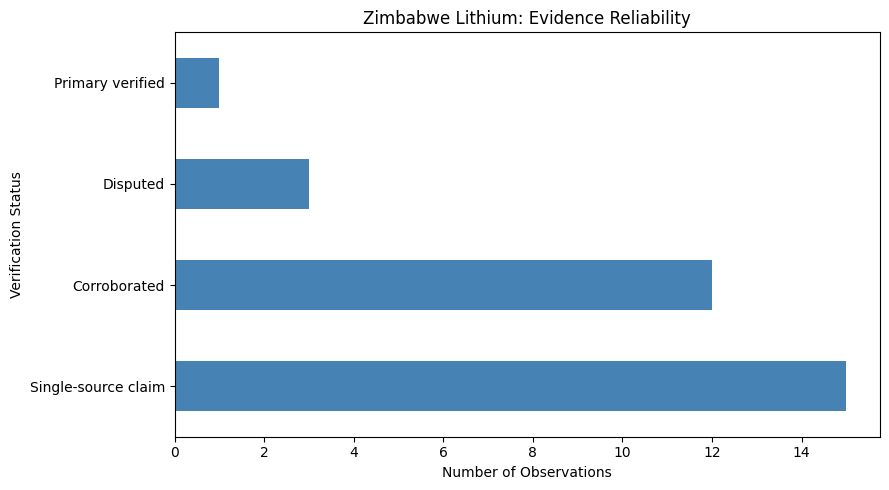

In [7]:
verification.plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Zimbabwe Lithium: Evidence Reliability")
plt.xlabel("Number of Observations")
plt.ylabel("Verification Status")
plt.tight_layout()
plt.show()

In [8]:
stronger_evidence = df[
    (df["Actual_or_Forecast"] == "Actual")
    &
    (df["Verification_Status"].isin([
        "Primary verified",
        "Corroborated"
    ]))
].copy()

print("Original observations:", len(df))
print("Filtered observations:", len(stronger_evidence))

Original observations: 31
Filtered observations: 13


In [9]:
stronger_evidence[
    [
        "Project_Name",
        "Year",
        "Indicator",
        "Standardised_Value",
        "Standardised_Unit",
        "Verification_Status"
    ]
]

,Project_Name,Year,Indicator,Standardised_Value,Standardised_Unit,Verification_Status
0,Arcadia-Huayou Cobalt,2021,Ore_Reserve_JORC,42300000,tonnes,Primary verified
1,Arcadia-Huayou Cobalt,2022,Acquisition_Price_Paid,422000000,USD,Corroborated
2,Arcadia-Huayou Cobalt,2023,Capex_Spent_Reported,300000000,USD,Corroborated
5,Arcadia-Huayou Cobalt,2025,Capex_Spent_Sulphate_Plant,400000000,USD,Corroborated
6,Arcadia-Huayou Cobalt,2025,Lithium_Sulphate_Capacity_SMM,50000,tonnes/year,Corroborated
9,Bikita Minerals,2022,Acquisition_Price_Paid,180000000,USD,Corroborated
11,Bikita Minerals,2023,Capex_Spent_Expansion,300000000,USD,Corroborated
12,Bikita Minerals,2023,Ore_Processing_Capacity,4000000,tonnes/year,Corroborated
13,Bikita Minerals,2023,Spodumene_Concentrate_Capacity,300000,tonnes/year,Corroborated
14,Bikita Minerals,2023,Petalite_Concentrate_Capacity,300000,tonnes/year,Corroborated


In [10]:
acquisition = stronger_evidence[
    stronger_evidence["Indicator"] == "Acquisition_Price_Paid"
].copy()

acquisition["USD_Million"] = (
    acquisition["Standardised_Value"] / 1000000
)

acquisition = acquisition.sort_values(
    "USD_Million", ascending=False
)

acquisition[["Project_Name", "Year", "USD_Million"]]

,Project_Name,Year,USD_Million
1,Arcadia-Huayou Cobalt,2022,422.0
9,Bikita Minerals,2022,180.0
19,Sabi Star Lithium-Tantalum Mine,2021,76.5


In [11]:
print("Total acquisition value:",
      acquisition["USD_Million"].sum())

print("Average acquisition value:",
      acquisition["USD_Million"].mean())

print("Median acquisition value:",
      acquisition["USD_Million"].median())

Total acquisition value: 678.5
Average acquisition value: 226.16666666666666
Median acquisition value: 180.0


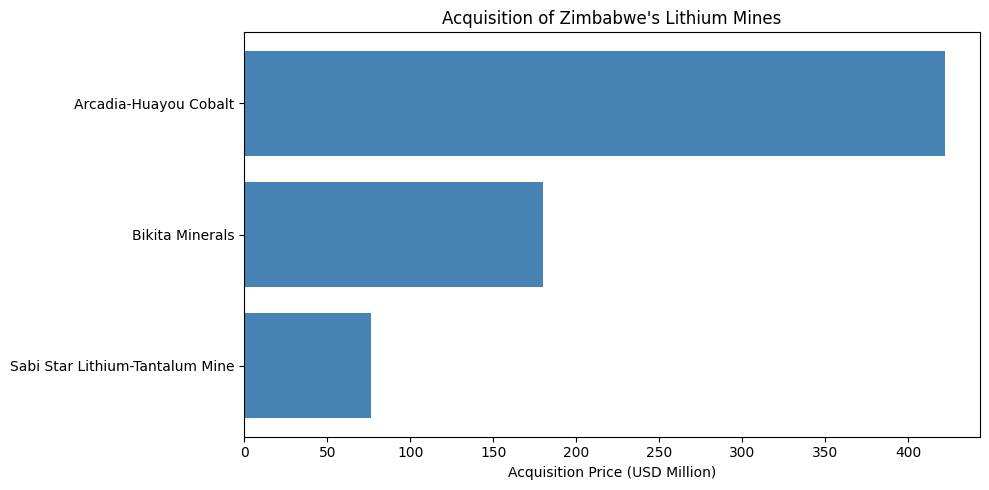

In [12]:
plt.figure(figsize=(10, 5))

plt.barh(
    acquisition["Project_Name"],
    acquisition["USD_Million"],
    color="steelblue"
)

plt.xlabel("Acquisition Price (USD Million)")
plt.title("Acquisition of Zimbabwe's Lithium Mines")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [13]:
capex = stronger_evidence[
    stronger_evidence["Indicator"].str.startswith("Capex_Spent")
].copy()

capex["USD_Million"] = capex["Standardised_Value"] / 1000000

capex[["Project_Name", "Year", "Indicator", "USD_Million"]]

,Project_Name,Year,Indicator,USD_Million
2,Arcadia-Huayou Cobalt,2023,Capex_Spent_Reported,300.0
5,Arcadia-Huayou Cobalt,2025,Capex_Spent_Sulphate_Plant,400.0
11,Bikita Minerals,2023,Capex_Spent_Expansion,300.0


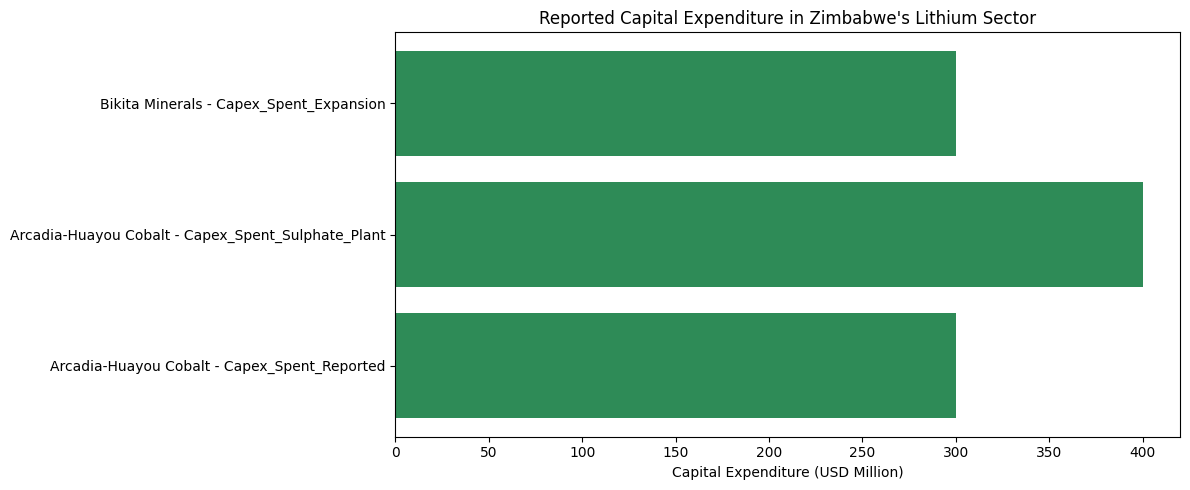

In [14]:
capex["Investment_Label"] = (
    capex["Project_Name"] + " - " +
    capex["Indicator"]
)

plt.figure(figsize=(12, 5))

plt.barh(
    capex["Investment_Label"],
    capex["USD_Million"],
    color="seagreen"
)

plt.xlabel("Capital Expenditure (USD Million)")
plt.title("Reported Capital Expenditure in Zimbabwe's Lithium Sector")
plt.tight_layout()
plt.show()

In [15]:
capacity = stronger_evidence[
    stronger_evidence["Indicator"].str.contains("Capacity")
    &
    (stronger_evidence["Standardised_Unit"] == "tonnes/year")
].copy()

capacity[[
    "Project_Name",
    "Year",
    "Indicator",
    "Standardised_Value",
    "Standardised_Unit"
]]

,Project_Name,Year,Indicator,Standardised_Value,Standardised_Unit
6,Arcadia-Huayou Cobalt,2025,Lithium_Sulphate_Capacity_SMM,50000,tonnes/year
12,Bikita Minerals,2023,Ore_Processing_Capacity,4000000,tonnes/year
13,Bikita Minerals,2023,Spodumene_Concentrate_Capacity,300000,tonnes/year
14,Bikita Minerals,2023,Petalite_Concentrate_Capacity,300000,tonnes/year
20,Sabi Star Lithium-Tantalum Mine,2023,Ore_Processing_Capacity,900000,tonnes/year


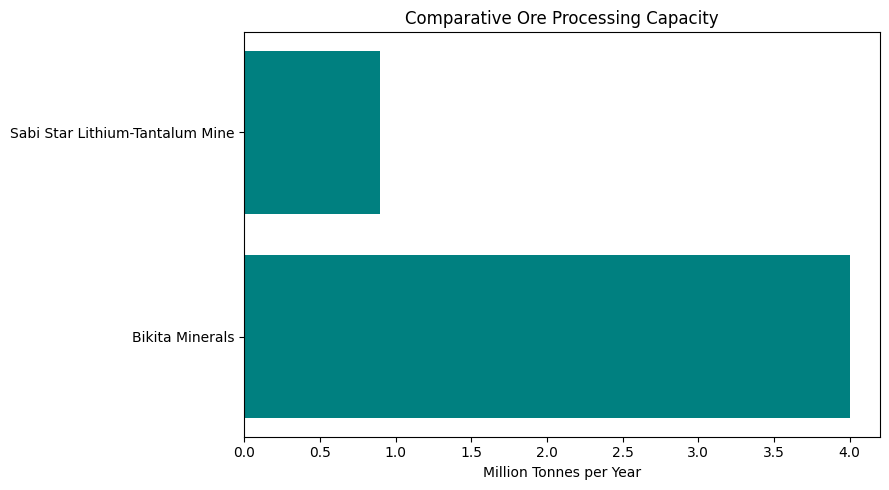

In [16]:
ore_capacity = capacity[
    capacity["Indicator"] == "Ore_Processing_Capacity"
].copy()

ore_capacity["Million_Tonnes"] = (
    ore_capacity["Standardised_Value"] / 1000000
)

plt.figure(figsize=(9, 5))

plt.barh(
    ore_capacity["Project_Name"],
    ore_capacity["Million_Tonnes"],
    color="teal"
)

plt.xlabel("Million Tonnes per Year")
plt.title("Comparative Ore Processing Capacity")
plt.tight_layout()
plt.show()

In [17]:
capacity_matrix = capacity.pivot_table(
    index="Project_Name",
    columns="Indicator",
    values="Standardised_Value",
    aggfunc="first"
)

capacity_matrix

Indicator,Lithium_Sulphate_Capacity_SMM,Ore_Processing_Capacity,Petalite_Concentrate_Capacity,Spodumene_Concentrate_Capacity
Project_Name,,,,
Arcadia-Huayou Cobalt,50000.0,NaN,NaN,NaN
Bikita Minerals,NaN,4000000.0,300000.0,300000.0
Sabi Star Lithium-Tantalum Mine,NaN,900000.0,NaN,NaN


In [18]:
print("Dataset shape:", national.shape)

print("\nColumn names:")
print(national.columns.tolist())

national

Dataset shape: (9, 7)

Column names:
['Production_Year', 'Lithium_Content_Metric_Tons', 'Source_File', 'Publication_Year', 'Reported_Status', 'Geographic_Scope', 'Integration_Rule']


,Production_Year,Lithium_Content_Metric_Tons,Source_File,Publication_Year,Reported_Status,Geographic_Scope,Integration_Rule
0,2015,1000,mcs-2016-lithi(1).pdf,2016,2015 estimate,Zimbabwe national total,"Context only; never allocate to Bikita, Arcadi..."
1,2016,900,mcs-2017-lithi.pdf,2017,2016 estimate,Zimbabwe national total,"Context only; never allocate to Bikita, Arcadi..."
2,2017,1000,mcs-2018-lithi.pdf,2018,2017 estimate,Zimbabwe national total,"Context only; never allocate to Bikita, Arcadi..."
3,2019,1600,mcs2020-lithium.pdf,2020,2019 estimate,Zimbabwe national total,"Context only; never allocate to Bikita, Arcadi..."
4,2020,1200,mcs2021-lithium.pdf,2021,2020 estimate,Zimbabwe national total,"Context only; never allocate to Bikita, Arcadi..."
5,2021,1200,mcs2022-lithium.pdf,2022,2021 estimate,Zimbabwe national total,"Context only; never allocate to Bikita, Arcadi..."
6,2022,800,mcs2023-lithium.pdf,2023,2022 estimate,Zimbabwe national total,"Context only; never allocate to Bikita, Arcadi..."
7,2024,22000,mcs2025-lithium.pdf,2025,2024 estimate,Zimbabwe national total,"Context only; never allocate to Bikita, Arcadi..."
8,2025,28000,mcs2026-lithium(1).pdf,2026,2025 estimate,Zimbabwe national total,"Context only; never allocate to Bikita, Arcadi..."


In [19]:
print(national.columns.tolist())

['Production_Year', 'Lithium_Content_Metric_Tons', 'Source_File', 'Publication_Year', 'Reported_Status', 'Geographic_Scope', 'Integration_Rule']


In [20]:
print(national.columns.tolist())

['Production_Year', 'Lithium_Content_Metric_Tons', 'Source_File', 'Publication_Year', 'Reported_Status', 'Geographic_Scope', 'Integration_Rule']


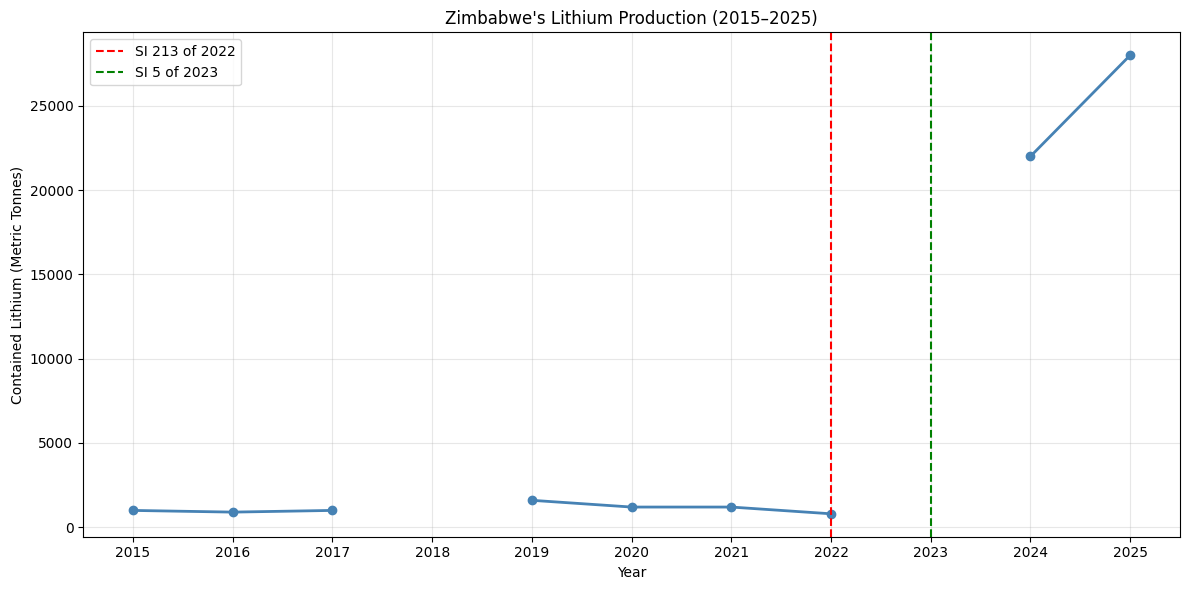

In [21]:
production = national.set_index(
    "Production_Year"
)["Lithium_Content_Metric_Tons"]

production = production.reindex(range(2015, 2026))

plt.figure(figsize=(12, 6))

plt.plot(
    production.index,
    production.values,
    marker="o",
    color="steelblue",
    linewidth=2
)

plt.axvline(
    x=2022, color="red",
    linestyle="--", label="SI 213 of 2022"
)

plt.axvline(
    x=2023, color="green",
    linestyle="--", label="SI 5 of 2023"
)

plt.title("Zimbabwe's Lithium Production (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Contained Lithium (Metric Tonnes)")
plt.xticks(range(2015, 2026))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
annual_growth = production.pct_change(
    fill_method=None
) * 100

growth_table = pd.DataFrame({
    "Production_Tonnes": production,
    "Annual_Growth_Percent": annual_growth.round(2)
})

growth_table

,Production_Tonnes,Annual_Growth_Percent
Production_Year,,
2015,1000.0,NaN
2016,900.0,-10.00
2017,1000.0,11.11
2018,NaN,NaN
2019,1600.0,NaN
2020,1200.0,-25.00
2021,1200.0,0.00
2022,800.0,-33.33
2023,NaN,NaN


In [23]:
start = production.loc[2022]
end = production.loc[2025]
years = 2025 - 2022

total_growth = ((end / start) - 1) * 100

cagr = ((end / start) ** (1 / years) - 1) * 100

print(f"Total growth: {total_growth:.2f}%")
print(f"CAGR: {cagr:.2f}%")
print(f"Production multiple: {end/start:.2f}x")

Total growth: 3400.00%
CAGR: 227.11%
Production multiple: 35.00x


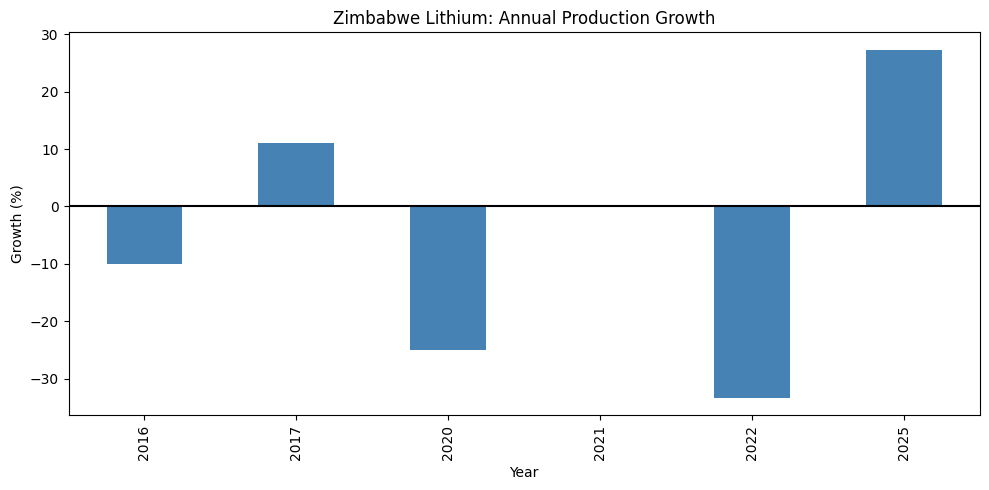

In [24]:
annual_growth.dropna().plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.axhline(0, color="black")
plt.title("Zimbabwe Lithium: Annual Production Growth")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.tight_layout()
plt.show()

In [25]:
pre_policy = production.loc[2015:2021]
transition = production.loc[2022:2023]
post_policy = production.loc[2024:2025]

comparison = pd.DataFrame({
    "Average_Production": [
        pre_policy.mean(),
        transition.mean(),
        post_policy.mean()
    ],
    "Available_Years": [
        pre_policy.count(),
        transition.count(),
        post_policy.count()
    ]
}, index=[
    "Pre-policy",
    "Transition",
    "Post-policy"
])

comparison.round(2)

,Average_Production,Available_Years
Pre-policy,1150.0,6
Transition,800.0,1
Post-policy,25000.0,2


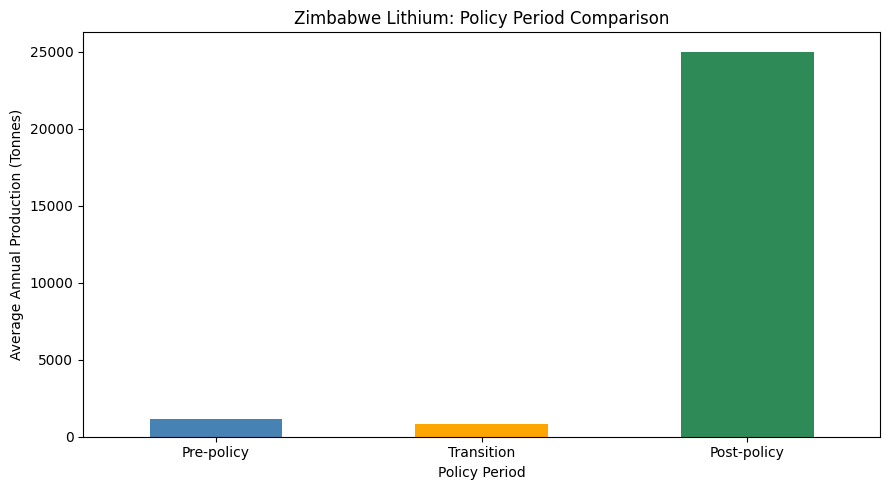

In [26]:
comparison["Average_Production"].plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange", "seagreen"]
)

plt.title("Zimbabwe Lithium: Policy Period Comparison")
plt.ylabel("Average Annual Production (Tonnes)")
plt.xlabel("Policy Period")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
ratio = post_policy.mean() / pre_policy.mean()

print(f"Post-policy production multiple: {ratio:.2f}x")

Post-policy production multiple: 21.74x


In [28]:
print("Evidence dataset shape:", evidence.shape)

print("\nColumn names:")
print(evidence.columns.tolist())

evidence.head()

Evidence dataset shape: (21, 9)

Column names:
['Evidence_ID', 'Hypothesis', 'Scope / Project_ID', 'Source_ID', 'PDF page', 'Extracted finding (paraphrase)', 'Evidence type', 'Direction', 'Limitation / verification action']


,Evidence_ID,Hypothesis,Scope / Project_ID,Source_ID,PDF page,Extracted finding (paraphrase),Evidence type,Direction,Limitation / verification action
0,EXT_001,H2,National,SRC_31,72–73,Ministry states export permits tied to benefic...,Official statement,Challenges blanket weak enforcement,"Request actual permits, inspection and reconci..."
1,EXT_002,H2,National,SRC_31,73,Responsible Mining Audits launched in 2023 and...,Official statement,Mixed,No mine-specific results established by this p...
2,EXT_003,H1/H2,National,SRC_34,260,Budget proposes 10% export tax on ore and conc...,Budget proposal,Mixed,Not enacted rate or tax paid; check Finance Act.
3,EXT_004,H2,National,SRC_35,342,2027 budget proposes concentrate export tax va...,Budget proposal,Mixed,Future implementation outside scope; confirm l...
4,EXT_005,H1/H2,National,SRC_33,29–30,OECD reports increase in processed exports aft...,Secondary analysis,Alternative explanation,Check underlying trade series and product clas...


In [29]:
print("Missing values:")
print(evidence.isnull().sum())

print("\nDuplicate rows:")
print(evidence.duplicated().sum())

Missing values:
Evidence_ID                         0
Hypothesis                          0
Scope / Project_ID                  0
Source_ID                           0
PDF page                            0
Extracted finding (paraphrase)      0
Evidence type                       0
Direction                           0
Limitation / verification action    0
dtype: int64

Duplicate rows:
0


In [30]:
justice_mask = evidence.astype(str).apply(
    lambda col: col.str.contains(
        "H3|distributive|procedural|recognition",
        case=False,
        regex=True
    )
).any(axis=1)

justice = evidence[justice_mask].copy()

print("Total evidence records:", len(evidence))
print("Climate justice candidate records:", len(justice))

display(justice)

Total evidence records: 21
Climate justice candidate records: 16


,Evidence_ID,Hypothesis,Scope / Project_ID,Source_ID,PDF page,Extracted finding (paraphrase),Evidence type,Direction,Limitation / verification action
5,EXT_006,H3,Six sites pooled,SRC_01,"16,43",230 convenience-sampled respondents; 91% unawa...,Survey perception,Supports procedural concern,Not representative population estimate; six si...
6,EXT_007,H3,Six sites pooled,SRC_01,44,94% felt input not valued; 13 of 230 reported ...,Survey perception,Supports procedural concern,Same sample; not independent observations.
7,EXT_008,H3,Zim_L1,SRC_01,44,59% believed no grievance mechanism existed; H...,Survey vs company interview,Conflicting,Distinguish existence from accessibility; requ...
8,EXT_009,H3,Zim_L2,SRC_01,46,39% positive responses on availability of jobs...,Survey perception,Mixed,Not employment rate; convenience sample; figur...
9,EXT_010,H3,Zim_L4,SRC_01,46,26% positive responses on availability of jobs...,Survey perception,Mixed,Not employment rate; convenience sample; figur...
10,EXT_011,H3,Zim_L1,SRC_01,46,23% positive responses on availability of jobs...,Survey perception,Mixed,Not employment rate; convenience sample; figur...
11,EXT_012,H3,Zim_L3,SRC_01,46,13% positive responses on availability of jobs...,Survey perception,Mixed,Not employment rate; convenience sample; figur...
12,EXT_013,H3,Zim_L2,SRC_36,4–5,80% of 100 Ward 11 study participants reported...,Survey perception,Counterbalances,Not objective measurement or population preval...
13,EXT_014,H3,Zim_L2,SRC_36,4–5,75% of 100 Ward 11 study participants reported...,Survey perception,Counterbalances,Not objective measurement or population preval...
14,EXT_015,H3,Zim_L2,SRC_36,4–5,70% of 100 Ward 11 study participants reported...,Survey perception,Supports,Not objective measurement or population preval...


In [31]:
justice_text = justice.astype(str).agg(" ".join, axis=1)

dimensions = {
    "Distributive": r"distributive|employment|pollution|compensation|benefits",
    "Procedural": r"procedural|consultation|participation|decision-making",
    "Recognition": r"recognition|customary|livelihood|displacement|land rights"
}

for dimension, pattern in dimensions.items():
    justice[dimension] = justice_text.str.contains(
        pattern, case=False, regex=True
    )

justice_summary = justice[list(dimensions)].sum()

print(justice_summary)

Distributive    8
Procedural      2
Recognition     2
dtype: int64


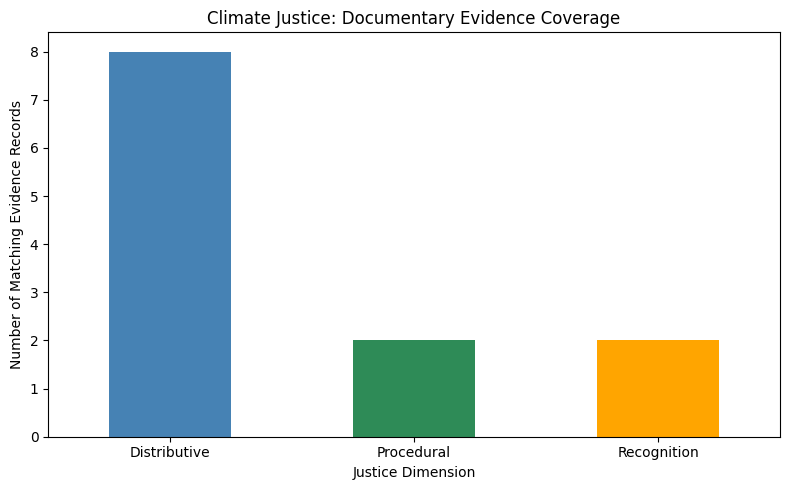

In [32]:
justice_summary.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "seagreen", "orange"]
)

plt.title("Climate Justice: Documentary Evidence Coverage")
plt.ylabel("Number of Matching Evidence Records")
plt.xlabel("Justice Dimension")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
bikita_justice = pd.DataFrame({
    "Indicator": [
        "Employment opportunities",
        "Improved infrastructure",
        "Unequal benefit distribution",
        "Disrupted traditional land use",
        "Displacement and land loss",
        "Water pollution"
    ],
    "Percentage": [80, 75, 70, 70, 60, 55],
    "Category": [
        "Benefit", "Benefit",
        "Cost", "Cost", "Cost", "Cost"
    ]
})

display(bikita_justice)

,Indicator,Percentage,Category
0,Employment opportunities,80,Benefit
1,Improved infrastructure,75,Benefit
2,Unequal benefit distribution,70,Cost
3,Disrupted traditional land use,70,Cost
4,Displacement and land loss,60,Cost
5,Water pollution,55,Cost


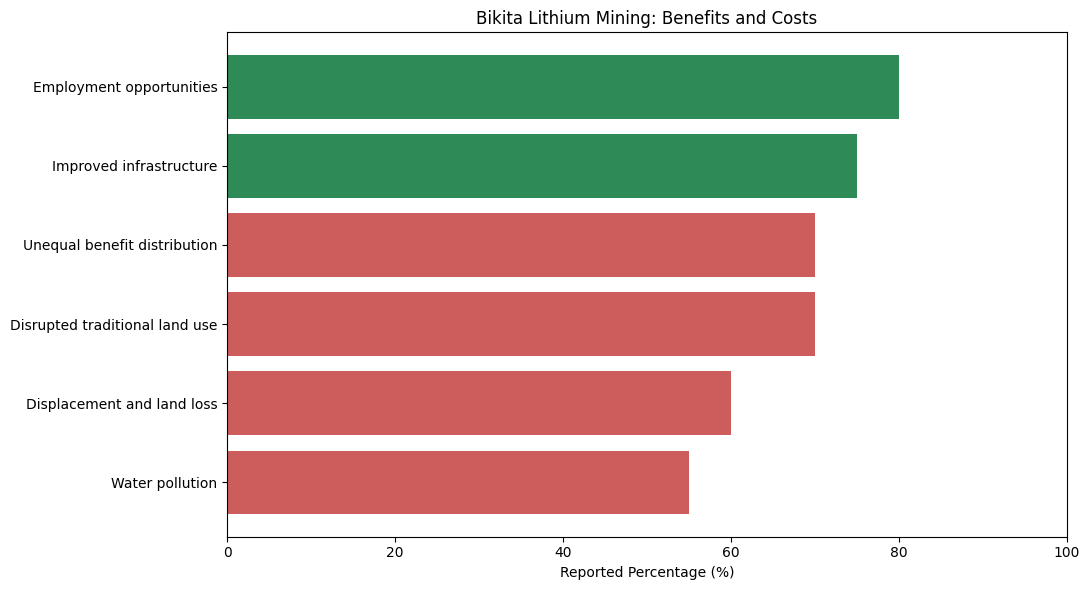

In [34]:
colors = bikita_justice["Category"].map({
    "Benefit": "seagreen",
    "Cost": "indianred"
})

plt.figure(figsize=(11, 6))

plt.barh(
    bikita_justice["Indicator"],
    bikita_justice["Percentage"],
    color=colors
)

plt.xlabel("Reported Percentage (%)")
plt.title("Bikita Lithium Mining: Benefits and Costs")
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [35]:
procedural = pd.DataFrame({
    "Indicator": [
        "Unaware of prior consultations",
        "Felt their input was not valued",
        "Participated in meetings"
    ],
    "Percentage": [91, 94, (13/230)*100]
})

procedural["Percentage"] = procedural["Percentage"].round(2)

display(procedural)

,Indicator,Percentage
0,Unaware of prior consultations,91.00
1,Felt their input was not valued,94.00
2,Participated in meetings,5.65


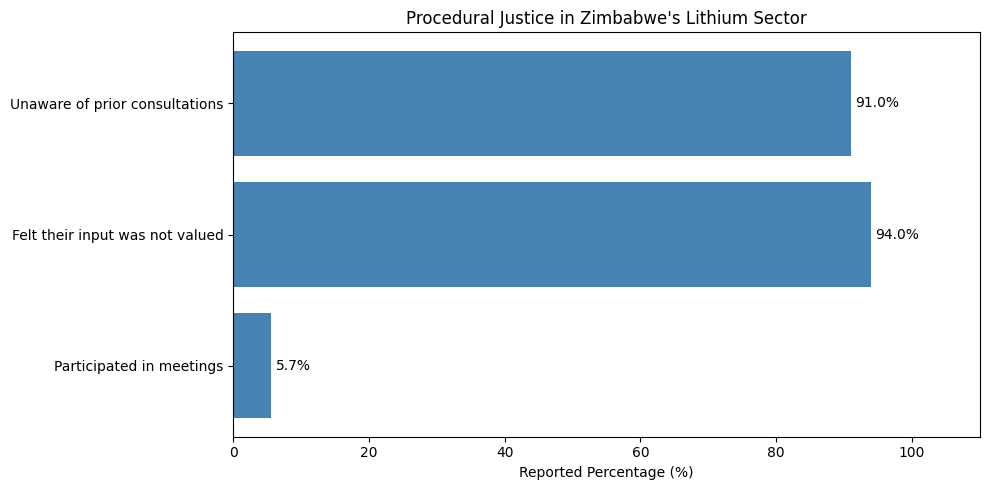

In [36]:
plt.figure(figsize=(10, 5))

bars = plt.barh(
    procedural["Indicator"],
    procedural["Percentage"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.xlabel("Reported Percentage (%)")
plt.title("Procedural Justice in Zimbabwe's Lithium Sector")
plt.xlim(0, 110)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [37]:
key_indicators = [
    "Acquisition_Price_Paid",
    "Capex_Spent_Reported",
    "Capex_Spent_Sulphate_Plant",
    "Capex_Spent_Expansion",
    "Ore_Processing_Capacity",
    "Lithium_Sulphate_Capacity_SMM"
]

comparative = stronger_evidence[
    stronger_evidence["Indicator"].isin(key_indicators)
].copy()

display(comparative)

,Observation_ID,Project_ID,Year,Indicator,Value,Unit,Standardised_Value,Standardised_Unit,Product_Form,Geographic_Level,Data_Status,Method_or_Definition,Source_IDs,Page_or_Table,Researcher_Note,Evidence_Type,Actual_or_Forecast,Verification_Status,Project_Name,Analysis_Flags
1,OBS_002,Zim_L1,2022,Acquisition_Price_Paid,422000000.0,USD,422000000,USD,Equity acquisition (87%->100% Arcadia),Mine,Verified documentary fact,Completed M&A acquisition price paid by Zhejia...,SRC_01; SRC_09,Table 5 / p. 38,Separate from post-acquisition capex,Academic,Actual,Corroborated,Arcadia-Huayou Cobalt,No structural flag
2,OBS_003,Zim_L1,2023,Capex_Spent_Reported,300000000.0,USD,300000000,USD,Concentrator plant capex,Mine,Company claim,Reported investment in lithium concentrator co...,SRC_09,Full article,Reclassified from verified fact to reported co...,Media,Actual,Corroborated,Arcadia-Huayou Cobalt,No structural flag
5,OBS_006,Zim_L1,2025,Capex_Spent_Sulphate_Plant,400000000.0,USD,400000000,USD,Lithium sulphate plant (completed Oct 2025),Mine,Company claim,Reported investment in Arcadia lithium sulphat...,SRC_08; SRC_32,Full article,Separated Oct 2025 construction completion fro...,Media,Actual,Corroborated,Arcadia-Huayou Cobalt,No structural flag
6,OBS_007,Zim_L1,2025,Lithium_Sulphate_Capacity_SMM,50000.0,tonnes/year,50000,tonnes/year,Lithium sulphate (Beneficiation Level 2),Mine,Company claim,SMM-reported annual plant capacity (completed ...,SRC_08; SRC_32,Full article,"Retained 50,000 tpa per SMM; alternative >60,0...",Media,Actual,Corroborated,Arcadia-Huayou Cobalt,Capacity not output
9,OBS_008,Zim_L2,2022,Acquisition_Price_Paid,180000000.0,USD,180000000,USD,Equity acquisition (74% Bikita via AMMS/SAMM),Mine,Verified documentary fact,Sinomine acquisition price announced Feb 2022,SRC_01; SRC_16,Table 5 / p. 38,Separate from post-acquisition expansion capex,Academic,Actual,Corroborated,Bikita Minerals,No structural flag
11,OBS_010,Zim_L2,2023,Capex_Spent_Expansion,300000000.0,USD,300000000,USD,Spodumene & petalite expansion capex,Mine,Company claim,Reported expenditure on 2023 expansion project...,SRC_01,p. 70 (Reuters 2023c),Separated from ore-processing and concentrate ...,Media,Actual,Corroborated,Bikita Minerals,No structural flag
12,OBS_010B,Zim_L2,2023,Ore_Processing_Capacity,4000000.0,tonnes/year,4000000,tonnes/year,Raw lithium ore (2M spodumene + 2M petalite),Mine,Company claim,Combined design ore-processing capacity of 202...,SRC_01; SRC_10,Full article,2M tpa spodumene line + 2M tpa petalite line,Company,Actual,Corroborated,Bikita Minerals,Capacity not output
19,OBS_015,Zim_L3,2021,Acquisition_Price_Paid,76500000.0,USD,76500000,USD,Equity acquisition (51% Max Mind Investments),Mine,Verified documentary fact,Chengxin Lithium acquisition of 51% stake (Nov...,SRC_01; SRC_02,p. 38 / p. 4,Reported as $76.5M-$77M across sources,Academic,Actual,Corroborated,Sabi Star Lithium-Tantalum Mine,No structural flag
20,OBS_016,Zim_L3,2023,Ore_Processing_Capacity,900000.0,tonnes/year,900000,tonnes/year,Raw lithium-tantalum ore,Mine,Verified documentary fact,Design annual ore processing capacity (commiss...,SRC_02,p. 5,"Produces 200,000-300,000 tpa concentrate depen...",Civil Society,Actual,Corroborated,Sabi Star Lithium-Tantalum Mine,Capacity not output


In [38]:
mine_matrix = comparative.pivot_table(
    index="Project_Name",
    columns="Indicator",
    values="Standardised_Value",
    aggfunc="first"
)

mine_matrix = mine_matrix.reindex(
    df["Project_Name"].unique()
)

display(mine_matrix)

Indicator,Acquisition_Price_Paid,Capex_Spent_Expansion,Capex_Spent_Reported,Capex_Spent_Sulphate_Plant,Lithium_Sulphate_Capacity_SMM,Ore_Processing_Capacity
Project_Name,,,,,,
Arcadia-Huayou Cobalt,422000000.0,NaN,300000000.0,400000000.0,50000.0,NaN
Bikita Minerals,180000000.0,300000000.0,NaN,NaN,NaN,4000000.0
Sabi Star Lithium-Tantalum Mine,76500000.0,NaN,NaN,NaN,NaN,900000.0
Sandawana Lithium Mine,NaN,NaN,NaN,NaN,NaN,NaN


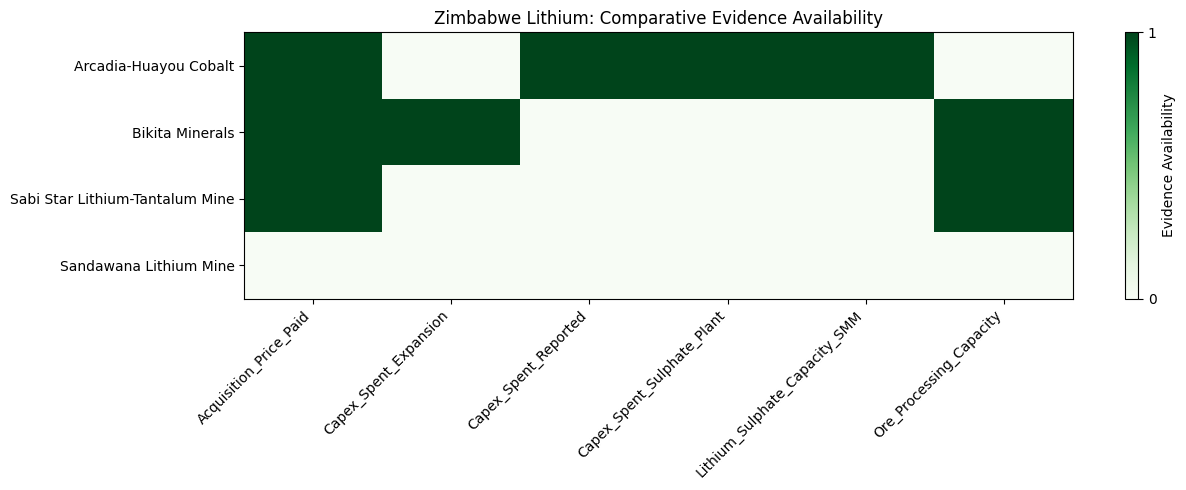

In [39]:
import numpy as np

availability = mine_matrix.notna().astype(int)

plt.figure(figsize=(13, 5))

plt.imshow(
    availability,
    cmap="Greens",
    aspect="auto",
    vmin=0,
    vmax=1
)

plt.xticks(
    range(len(availability.columns)),
    availability.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(availability.index)),
    availability.index
)

plt.title("Zimbabwe Lithium: Comparative Evidence Availability")
plt.colorbar(ticks=[0, 1], label="Evidence Availability")
plt.tight_layout()
plt.show()

In [40]:
import os

os.makedirs("outputs/charts", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)

print("Research output folders created successfully.")

Research output folders created successfully.


In [41]:
datasets = {
    "verified_observations": stronger_evidence,
    "acquisition_analysis": acquisition,
    "capital_expenditure": capex,
    "processing_capacity": capacity,
    "beneficiation_matrix": capacity_matrix,
    "national_production_growth": growth_table,
    "policy_period_comparison": comparison,
    "climate_justice_evidence": justice,
    "bikita_climate_justice": bikita_justice,
    "procedural_justice": procedural,
    "comparative_mine_matrix": mine_matrix,
    "evidence_availability": availability
}

for name, dataset in datasets.items():
    dataset.to_csv(f"outputs/tables/{name}.csv")

print(f"{len(datasets)} analytical datasets exported.")

12 analytical datasets exported.


In [42]:
for file in sorted(os.listdir("outputs/tables")):
    print(file)

acquisition_analysis.csv
beneficiation_matrix.csv
bikita_climate_justice.csv
capital_expenditure.csv
climate_justice_evidence.csv
comparative_mine_matrix.csv
evidence_availability.csv
national_production_growth.csv
policy_period_comparison.csv
procedural_justice.csv
processing_capacity.csv
verified_observations.csv


In [45]:
def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        f"outputs/charts/{filename}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close()

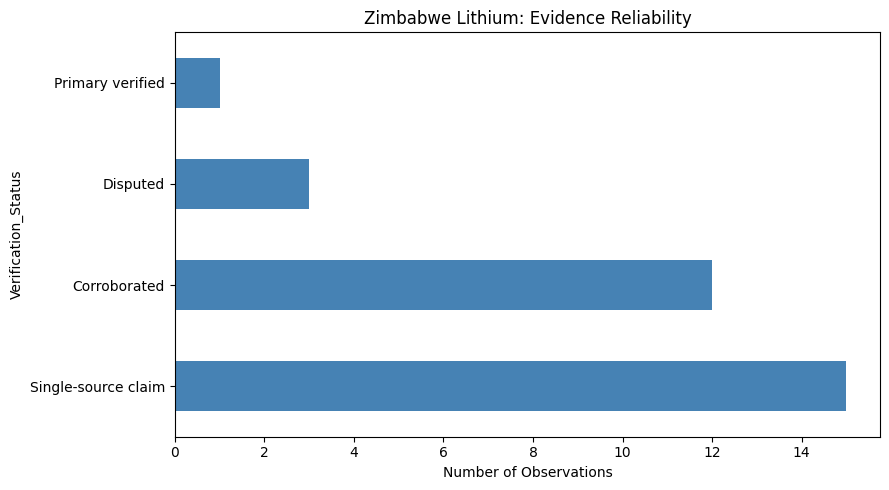

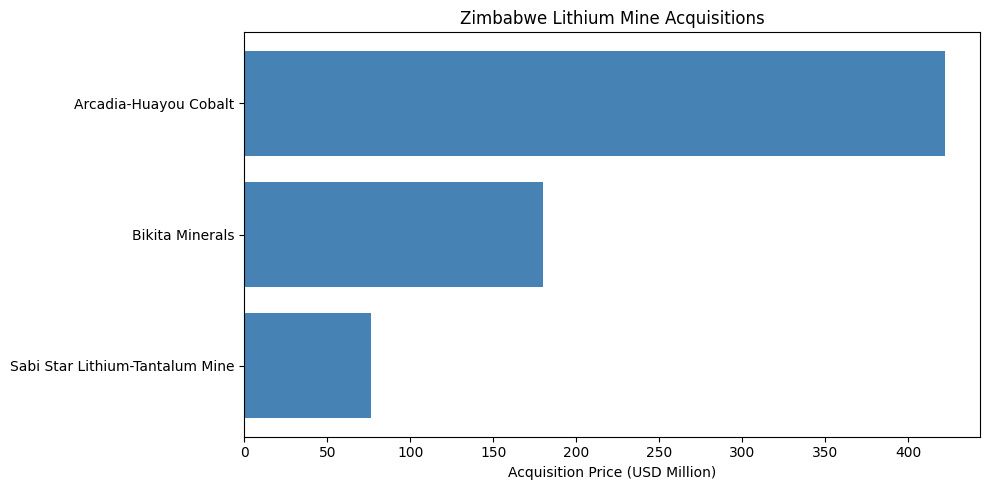

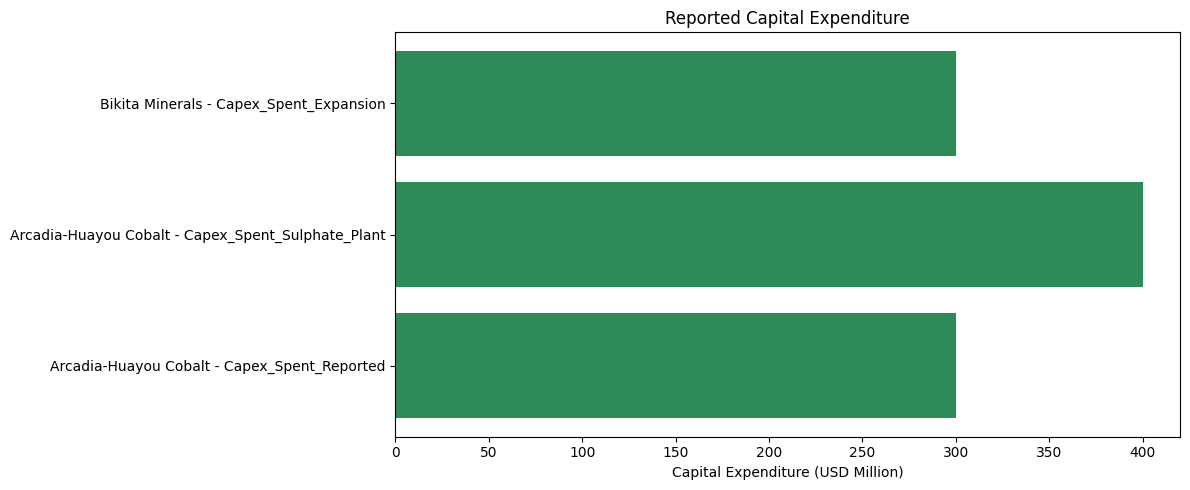

In [46]:
# Chart 1: Evidence reliability

verification.plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Zimbabwe Lithium: Evidence Reliability")
plt.xlabel("Number of Observations")

save_chart("01_evidence_reliability")


# Chart 2: Acquisition prices

plt.figure(figsize=(10, 5))

plt.barh(
    acquisition["Project_Name"],
    acquisition["USD_Million"],
    color="steelblue"
)

plt.xlabel("Acquisition Price (USD Million)")
plt.title("Zimbabwe Lithium Mine Acquisitions")
plt.gca().invert_yaxis()

save_chart("02_acquisition_prices")


# Chart 3: Capital expenditure

plt.figure(figsize=(12, 5))

plt.barh(
    capex["Investment_Label"],
    capex["USD_Million"],
    color="seagreen"
)

plt.xlabel("Capital Expenditure (USD Million)")
plt.title("Reported Capital Expenditure")

save_chart("03_capital_expenditure")

In [47]:
print(os.listdir("outputs/charts"))

['02_acquisition_prices.png', '03_capital_expenditure.png', '01_evidence_reliability.png']


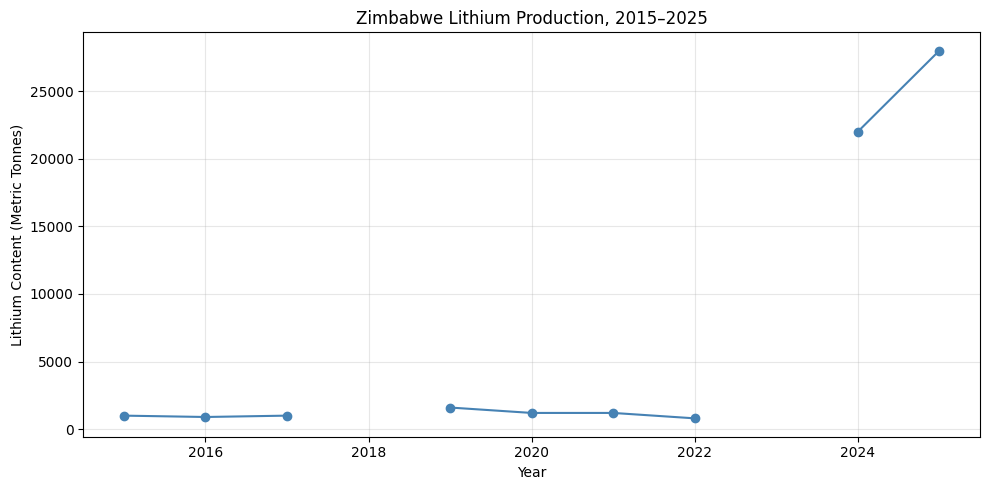

In [48]:
production.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Zimbabwe Lithium Production, 2015–2025")
plt.xlabel("Year")
plt.ylabel("Lithium Content (Metric Tonnes)")
plt.grid(alpha=0.3)

save_chart("04_national_production")

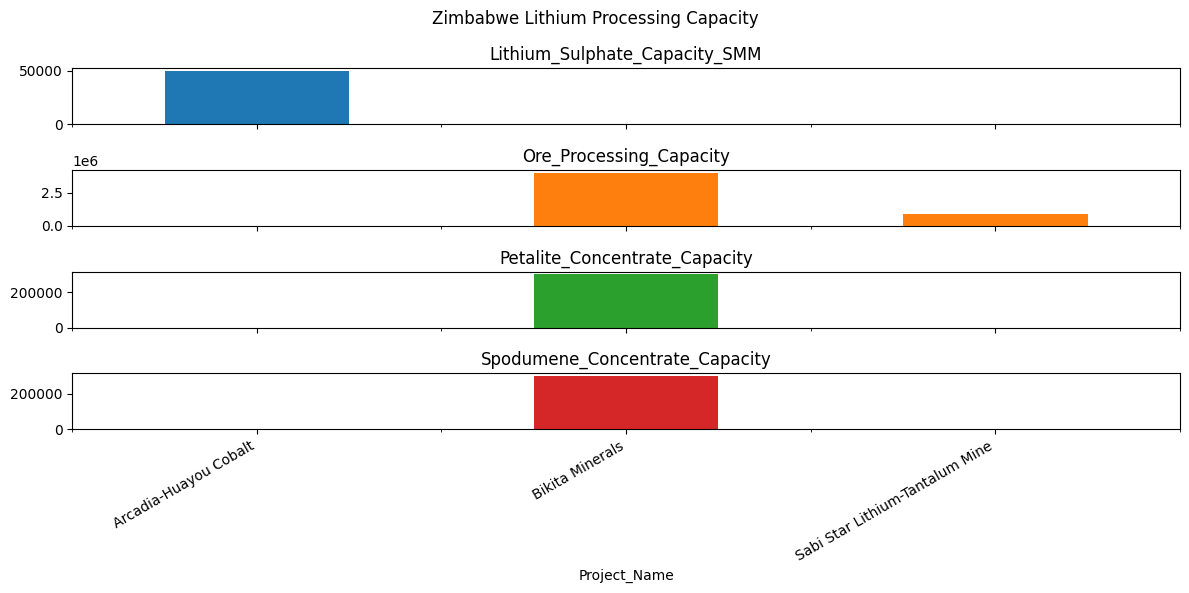

In [49]:
capacity_matrix.plot(
    kind="bar",
    figsize=(12, 6),
    subplots=True,
    sharex=True,
    legend=False
)

plt.suptitle("Zimbabwe Lithium Processing Capacity")
plt.xticks(rotation=30, ha="right")

save_chart("05_beneficiation_capacity")

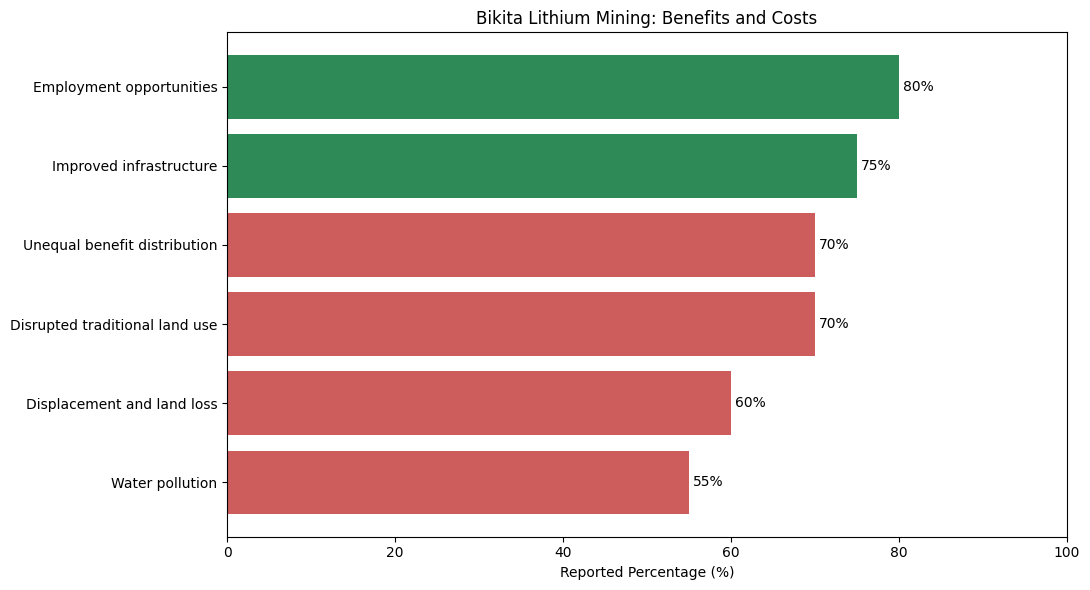

In [50]:
plt.figure(figsize=(11, 6))

colors = bikita_justice["Category"].map({
    "Benefit": "seagreen",
    "Cost": "indianred"
})

bars = plt.barh(
    bikita_justice["Indicator"],
    bikita_justice["Percentage"],
    color=colors
)

plt.bar_label(bars, fmt="%.0f%%", padding=3)
plt.xlabel("Reported Percentage (%)")
plt.title("Bikita Lithium Mining: Benefits and Costs")
plt.xlim(0, 100)
plt.gca().invert_yaxis()

save_chart("06_bikita_climate_justice")

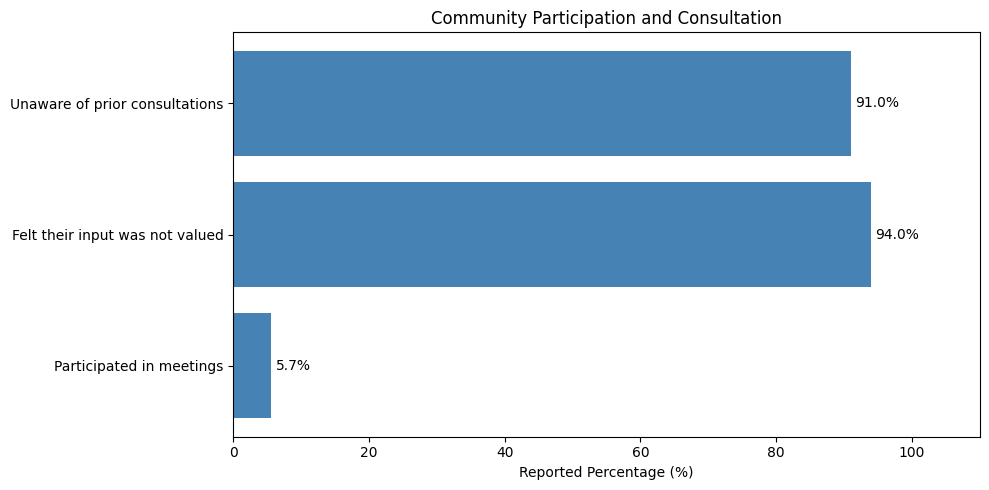

In [51]:
plt.figure(figsize=(10, 5))

bars = plt.barh(
    procedural["Indicator"],
    procedural["Percentage"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.xlabel("Reported Percentage (%)")
plt.title("Community Participation and Consultation")
plt.xlim(0, 110)
plt.gca().invert_yaxis()

save_chart("07_procedural_justice")

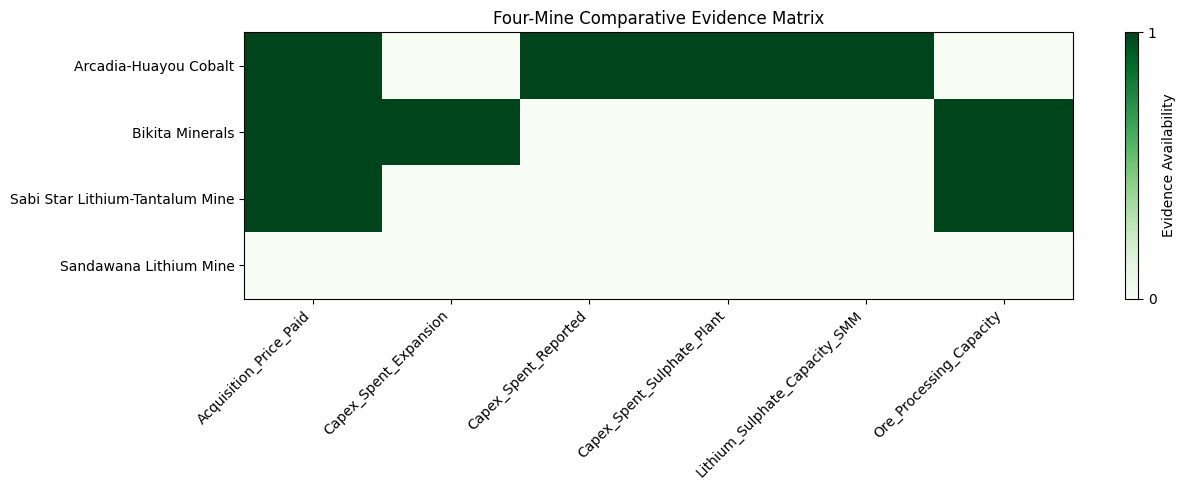

In [52]:
plt.figure(figsize=(13, 5))

plt.imshow(
    availability,
    cmap="Greens",
    aspect="auto",
    vmin=0,
    vmax=1
)

plt.xticks(
    range(len(availability.columns)),
    availability.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(availability.index)),
    availability.index
)

plt.colorbar(ticks=[0, 1], label="Evidence Availability")
plt.title("Four-Mine Comparative Evidence Matrix")

save_chart("08_comparative_evidence")

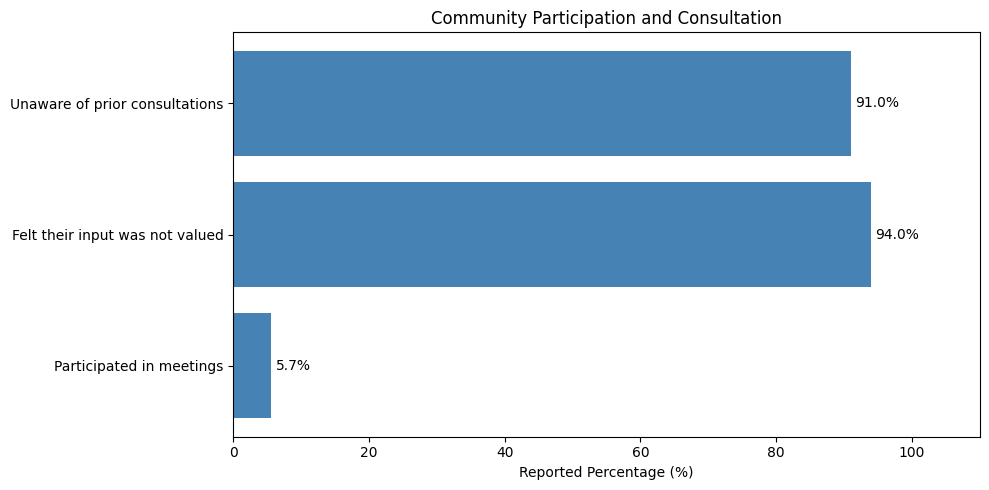

In [53]:
plt.figure(figsize=(10, 5))

bars = plt.barh(
    procedural["Indicator"],
    procedural["Percentage"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.xlabel("Reported Percentage (%)")
plt.title("Community Participation and Consultation")
plt.xlim(0, 110)
plt.gca().invert_yaxis()

save_chart("07_procedural_justice")

In [ ]:
plt.figure(figsize=(13, 5))

plt.imshow(
    availability,
    cmap="Greens",
    aspect="auto",
    vmin=0,
    vmax=1
)

plt.xticks(
    range(len(availability.columns)),
    availability.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(availability.index)),
    availability.index
)

plt.colorbar(ticks=[0, 1], label="Evidence Availability")
plt.title("Four-Mine Comparative Evidence Matrix")

save_chart("08_comparative_evidence")

In [54]:
charts = sorted(os.listdir("outputs/charts"))

for chart in charts:
    print(chart)

print("\nTotal charts:", len(charts))

01_evidence_reliability.png
02_acquisition_prices.png
03_capital_expenditure.png
04_national_production.png
05_beneficiation_capacity.png
06_bikita_climate_justice.png
07_procedural_justice.png
08_comparative_evidence.png

Total charts: 8


In [55]:
from pathlib import Path

csv_files = list(Path("outputs/tables").glob("*.csv"))
png_files = list(Path("outputs/charts").glob("*.png"))

print("Analytical datasets:", len(csv_files))
print("Research charts:", len(png_files))

assert len(csv_files) == 12
assert len(png_files) == 8

print("Portfolio validation successful!")

Analytical datasets: 12
Research charts: 8
Portfolio validation successful!


In [56]:
readme = """# Stage 6: Exploratory Data Analysis

## Research Project
Green Extractivism and Climate Justice:
A Case Study of Lithium Governance in Zimbabwe (2015–2026).

## Case Studies
- Bikita Minerals
- Arcadia Lithium Mine
- Sabi Star Lithium Mine
- Sandawana Lithium Mine

## Analytical Components
- Data quality and evidence reliability
- Foreign investment and acquisition analysis
- Mineral processing and beneficiation
- National lithium production trends
- Policy period comparison
- Climate justice and community participation
- Comparative evidence availability

## Tools
Python, Pandas, NumPy, Matplotlib and Google Colab.

## Research Outputs
- 12 analytical CSV datasets
- 8 high-resolution research charts

## Limitations
This is preliminary exploratory research.
Missing observations do not indicate zero activity.
Processing capacity does not represent actual production.
Survey findings are not nationally representative.
Descriptive associations do not establish causality.
Source verification remains ongoing.
"""

with open("outputs/README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("Documentation created successfully.")

Documentation created successfully.


In [57]:
import shutil
from google.colab import files

shutil.make_archive(
    "Zimbabwe_Lithium_Stage6_Outputs",
    "zip",
    "outputs"
)

files.download("Zimbabwe_Lithium_Stage6_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>